# 5 — Figures and tables of the paper

All the experiments of the paper, on held-out Mayo slices, in the order of the paper:

1. read-out of the learned scheme: iterate $x_n$ or resolvent output $d_n$;
2. safeguard ablation, without restart;
3. the chosen scheme (with restart) against the baselines: zero deviation, random deviations, learned without safeguard;
4. PSNR and reconstructions;
5. time per iteration;
6. the models trained at $128\times128$ (with and without the safeguard) applied at $512\times512$.

Every experiment is run on 10 slices of the test patient. The curves show the mean over the slices
(geometric mean for the objective gap, which is on a log scale); the spread over the slices is in
the tables (mean $\pm$ std, number of slices where a method beats zero deviation). Images and
timings use the first slice.

Every option of a run is a keyword of `run_fbs`: `restart`, `read_out`
(by default, the read-out the model was trained with, and a restart after the $T$ learned iterations).
The checkpoints are written by `main.py` (options `USE_SAFEGUARD`, `READ_OUT`).

Figures and tables are saved in `plots/` (prefix `5_`).

In [1]:
import os

import numpy as np
import pandas as pd
import torch

from utils.experiments import (build_test_instance, reference_solution, run_fbs, objective_gap,
                               time_table, load_model, random_direction)
from utils.plots import apply_paper_style, plot_curves, show_images

apply_paper_style()

In [2]:
# --- configuration (must match main.py) ---------------------------------------
SIZE = 512
N_ANGLES = 360
PHOTONS_PER_RAY = 10_000
GAMMA = 2
PRIMAL_STEP = 1.75         # primal step tau (see main.py)

TEST_PATIENT = "L014"      # never used for training or validation
TEST_SLICES = list(range(0, 150, 15))   # 10 slices out of 154; the first one for images and timings
MAYO_CACHE_DIR = "./data/mayo_cache_512"

# checkpoints written by main.py (SIZE, USE_SAFEGUARD, READ_OUT)
CKPT_D = "model_512.pt"                 # read-out d, safeguard
CKPT_D_NOSAFE = "model_512_nosafe.pt"   # read-out d, no safeguard
CKPT_X = "model_512_x.pt"               # read-out x, safeguard
CKPT_128 = "model_128.pt"               # read-out d, safeguard, trained at 128x128
CKPT_128_NOSAFE = "model_128_nosafe.pt" # read-out d, no safeguard, trained at 128x128

T_TRAIN = 10               # unrolling horizon used in training
T_LONG = 100               # length of the convergence curves
T_REF = 6000               # length of the run that defines F* (cached in results/)

In [3]:
instances, refs = [], []
for s in TEST_SLICES:
    inst = build_test_instance(SIZE, N_ANGLES, 0, GAMMA, TEST_PATIENT, s, MAYO_CACHE_DIR,
                               primal_step=PRIMAL_STEP, photons_per_ray=PHOTONS_PER_RAY)
    instances.append(inst)
    refs.append(reference_solution(inst, T_REF))
    print(f"slice {s}: F* = {refs[-1]['f_star']:.4f}, PSNR of the TGV2 solution = {refs[-1]['psnr']:.2f} dB")

model_d, ckpt_d = load_model(CKPT_D, instances[0], T=T_TRAIN)
model_d_nosafe, _ = load_model(CKPT_D_NOSAFE, instances[0], T=T_TRAIN)
model_x, ckpt_x = load_model(CKPT_X, instances[0], T=T_TRAIN)


def run_all(runs):
    # runs: {label: function inst -> result}; returns {label: [result on every slice]}
    return {label: [run(inst) for inst in instances] for label, run in runs.items()}


def gaps(results):
    # {label: array (n_slices, n_iterations)} of F - F*
    return {label: np.stack([objective_gap(r, ref["f_star"]) for r, ref in zip(rs, refs)])
            for label, rs in results.items()}


def gap_plot(results, name, horizon=T_TRAIN):
    plot_curves(gaps(results), r"$F(u_n, w_n) - F^\star$", name, slopes=True, horizon=horizon,
                iteration_start=0, show=True)


def psnr_plot(results, name):
    plot_curves({label: np.stack([r["psnr"] for r in rs]) for label, rs in results.items()},
                "PSNR (dB)", name, loglog=False, horizon=T_TRAIN,
                hline=(np.mean([ref["psnr"] for ref in refs]), r"TGV$^2$ solution (mean)"),
                iteration_start=0, show=True)


def summary(results, name, baseline="Zero deviation", iterations=(10, 100)):
    # mean +- std over the slices; number of slices where the method beats the baseline
    g = gaps(results)
    rows = []
    for label, rs in results.items():
        psnr = np.stack([r["psnr"] for r in rs])
        row = {"Method": label}
        for n in iterations:
            row[f"F-F*, {n} it."] = rf"{g[label][:, n].mean():.3g} $\pm$ {g[label][:, n].std():.2g}"
            row[f"PSNR, {n} it. (dB)"] = rf"{psnr[:, n].mean():.2f} $\pm$ {psnr[:, n].std():.2f}"
        if label != baseline:
            wins = int((g[label][:, iterations[0]] < g[baseline][:, iterations[0]]).sum())
            row[f"better at {iterations[0]} it."] = f"{wins}/{len(rs)}"
        rows.append(row)
    table = pd.DataFrame(rows).set_index("Method").fillna("")
    os.makedirs("plots", exist_ok=True)
    with open(os.path.join("plots", f"{name}.tex"), "w") as file:
        file.write(table.to_latex(escape=False))   # labels hold LaTeX math
    return table

slice 0: F* = 3.3422, PSNR of the TGV2 solution = 29.08 dB
slice 15: F* = 6.5580, PSNR of the TGV2 solution = 26.02 dB
slice 30: F* = 5.4471, PSNR of the TGV2 solution = 26.71 dB
slice 45: F* = 5.7532, PSNR of the TGV2 solution = 27.42 dB
slice 60: F* = 6.4906, PSNR of the TGV2 solution = 26.84 dB
slice 75: F* = 4.6142, PSNR of the TGV2 solution = 28.54 dB
slice 90: F* = 6.3476, PSNR of the TGV2 solution = 27.30 dB
slice 105: F* = 8.8912, PSNR of the TGV2 solution = 25.20 dB
slice 120: F* = 10.6736, PSNR of the TGV2 solution = 23.01 dB
slice 135: F* = 2.3157, PSNR of the TGV2 solution = 29.81 dB


## Training curves

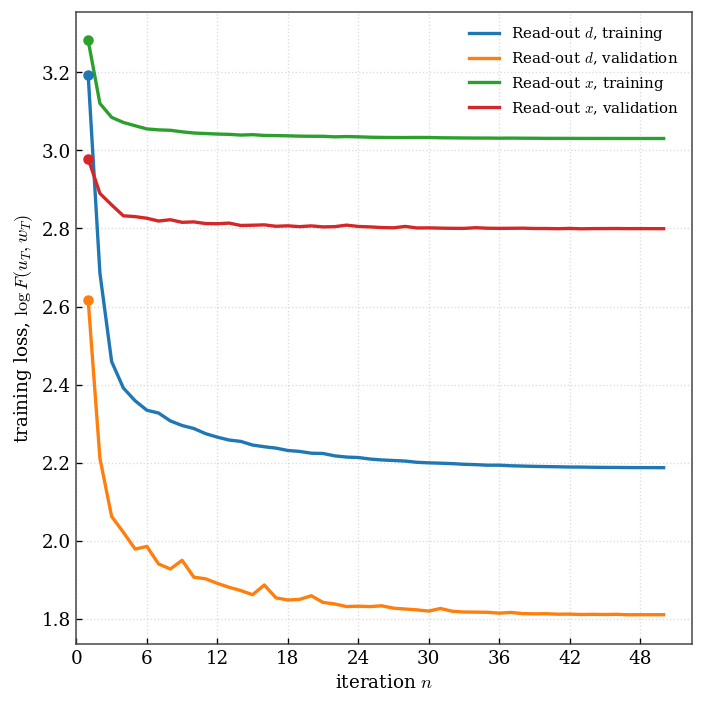

In [4]:
plot_curves({"Read-out $d$, training": ckpt_d["train_loss_history"],
             "Read-out $d$, validation": ckpt_d["val_loss_history"],
             "Read-out $x$, training": ckpt_x["train_loss_history"],
             "Read-out $x$, validation": ckpt_x["val_loss_history"]},
            r"training loss, $\log F(u_T, w_T)$", "5_training", loglog=False, show=True)

## 1. Read-out: $x_n$ or $d_n$

Both models are trained with the safeguard, on the objective read at their own read-out, and
are run here without restart. Each one is compared with the zero-deviation scheme read in the same way.

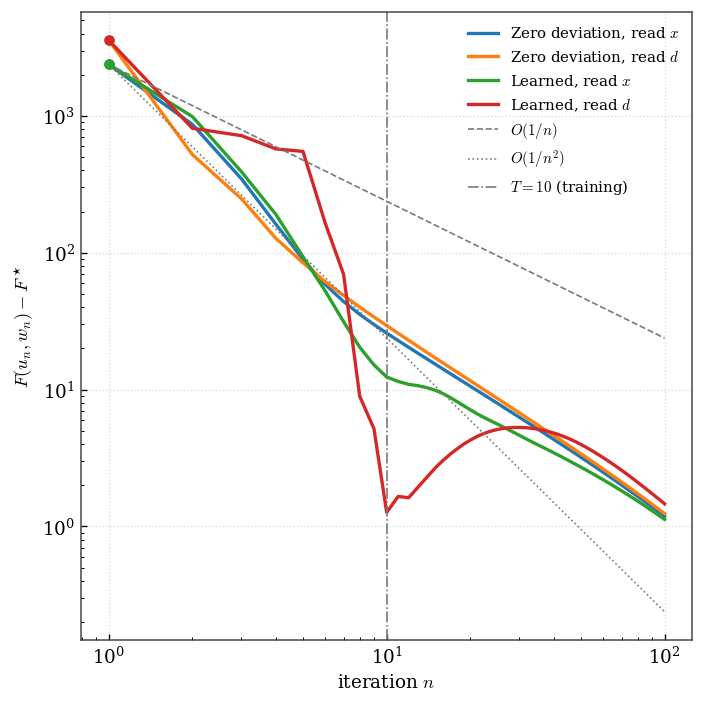

,"F-F*, 10 it.","PSNR, 10 it. (dB)","F-F*, 100 it.","PSNR, 100 it. (dB)",better at 10 it.
Method,,,,,
"Zero deviation, read $x$",26.9 $\pm$ 8,18.99 $\pm$ 0.71,1.22 $\pm$ 0.31,24.68 $\pm$ 0.40,10/10
"Zero deviation, read $d$",30.6 $\pm$ 9.1,18.79 $\pm$ 0.73,1.27 $\pm$ 0.32,24.61 $\pm$ 0.39,
"Learned, read $x$",13.2 $\pm$ 5.3,19.99 $\pm$ 0.71,1.16 $\pm$ 0.3,24.77 $\pm$ 0.41,10/10
"Learned, read $d$",1.91 $\pm$ 2.5,25.75 $\pm$ 1.59,1.5 $\pm$ 0.35,24.37 $\pm$ 0.39,10/10


In [5]:
readout = run_all({
    "Zero deviation, read $x$": lambda inst: run_fbs(inst, T_LONG, read_out="x"),
    "Zero deviation, read $d$": lambda inst: run_fbs(inst, T_LONG, read_out="d"),
    "Learned, read $x$": lambda inst: run_fbs(inst, T_LONG, model_x, restart=False),
    "Learned, read $d$": lambda inst: run_fbs(inst, T_LONG, model_d, restart=False),
})
gap_plot(readout, "5_readout")
summary(readout, "5_readout", baseline="Zero deviation, read $d$")

## 2. Safeguard ablation (no restart)

Read-out $d$: the model trained with the safeguard and the model trained without it.
Read-out $x$: the model trained with the safeguard.

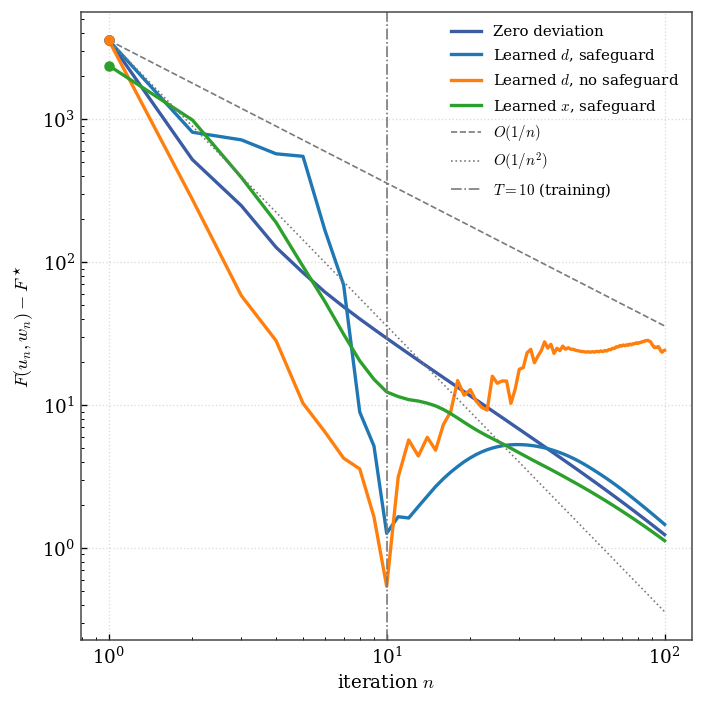

,"F-F*, 10 it.","PSNR, 10 it. (dB)","F-F*, 100 it.","PSNR, 100 it. (dB)",better at 10 it.
Method,,,,,
Zero deviation,30.6 $\pm$ 9.1,18.79 $\pm$ 0.73,1.27 $\pm$ 0.32,24.61 $\pm$ 0.39,
"Learned $d$, safeguard",1.91 $\pm$ 2.5,25.75 $\pm$ 1.59,1.5 $\pm$ 0.35,24.37 $\pm$ 0.39,10/10
"Learned $d$, no safeguard",0.602 $\pm$ 0.32,27.40 $\pm$ 0.91,26.2 $\pm$ 8.5,20.64 $\pm$ 1.06,10/10
"Learned $x$, safeguard",13.2 $\pm$ 5.3,19.99 $\pm$ 0.71,1.16 $\pm$ 0.3,24.77 $\pm$ 0.41,10/10


In [6]:
safeguard = dict(
    {"Zero deviation": readout["Zero deviation, read $d$"],
     "Learned $d$, safeguard": readout["Learned, read $d$"]},
    **run_all({"Learned $d$, no safeguard":
                   lambda inst: run_fbs(inst, T_LONG, model_d_nosafe, restart=False)}),
    **{"Learned $x$, safeguard": readout["Learned, read $x$"]},
)
gap_plot(safeguard, "5_safeguard_ablation")
summary(safeguard, "5_safeguard_ablation")

## 3. Chosen scheme against the baselines

The chosen model, with a restart after its $T$ learned iterations, and the model trained
without the safeguard (same restart).

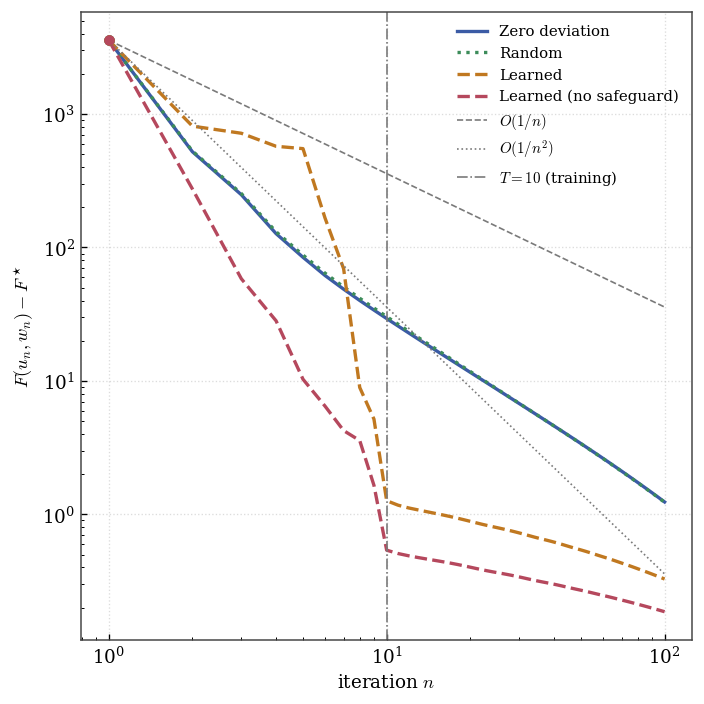

,"F-F*, 10 it.","PSNR, 10 it. (dB)","F-F*, 100 it.","PSNR, 100 it. (dB)",better at 10 it.
Method,,,,,
Zero deviation,30.6 $\pm$ 9.1,18.79 $\pm$ 0.73,1.27 $\pm$ 0.32,24.61 $\pm$ 0.39,
Random,31.5 $\pm$ 9.1,18.80 $\pm$ 0.73,1.26 $\pm$ 0.31,24.62 $\pm$ 0.40,0/10
Learned,1.91 $\pm$ 2.5,25.75 $\pm$ 1.59,0.365 $\pm$ 0.19,26.63 $\pm$ 0.83,10/10
Learned (no safeguard),0.602 $\pm$ 0.32,27.40 $\pm$ 0.91,0.229 $\pm$ 0.17,27.43 $\pm$ 1.09,10/10


In [7]:
BEST = model_d             # chosen from sections 1 and 2

results = dict(
    {"Zero deviation": safeguard["Zero deviation"]},
    **run_all({
        "Random": lambda inst: run_fbs(inst, T_LONG, random_direction()),
        "Learned": lambda inst: run_fbs(inst, T_LONG, BEST),
        "Learned (no safeguard)": lambda inst: run_fbs(inst, T_LONG, model_d_nosafe),
    }),
)
gap_plot(results, "5_objective_gap")
summary(results, "5_comparison")

## 4. PSNR and reconstructions

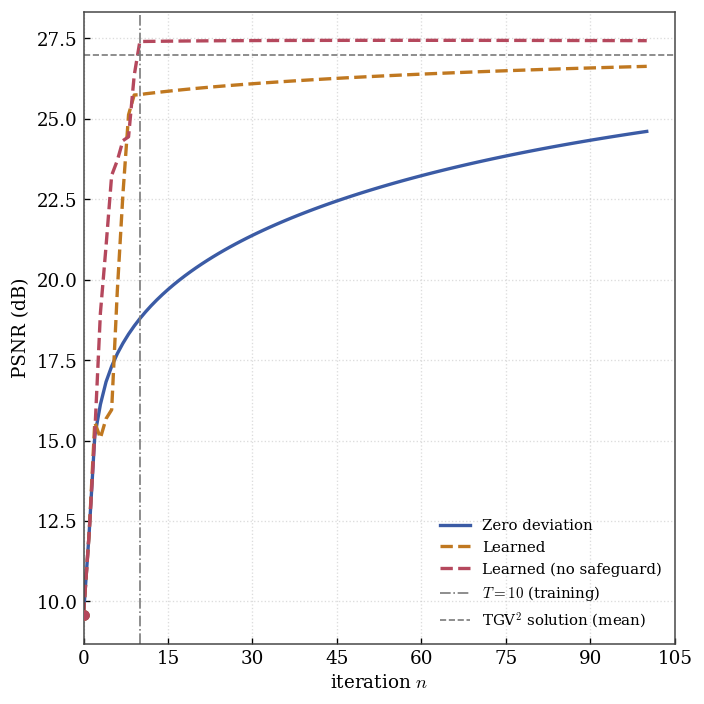

In [8]:
psnr_plot({label: rs for label, rs in results.items() if label != "Random"}, "5_psnr")

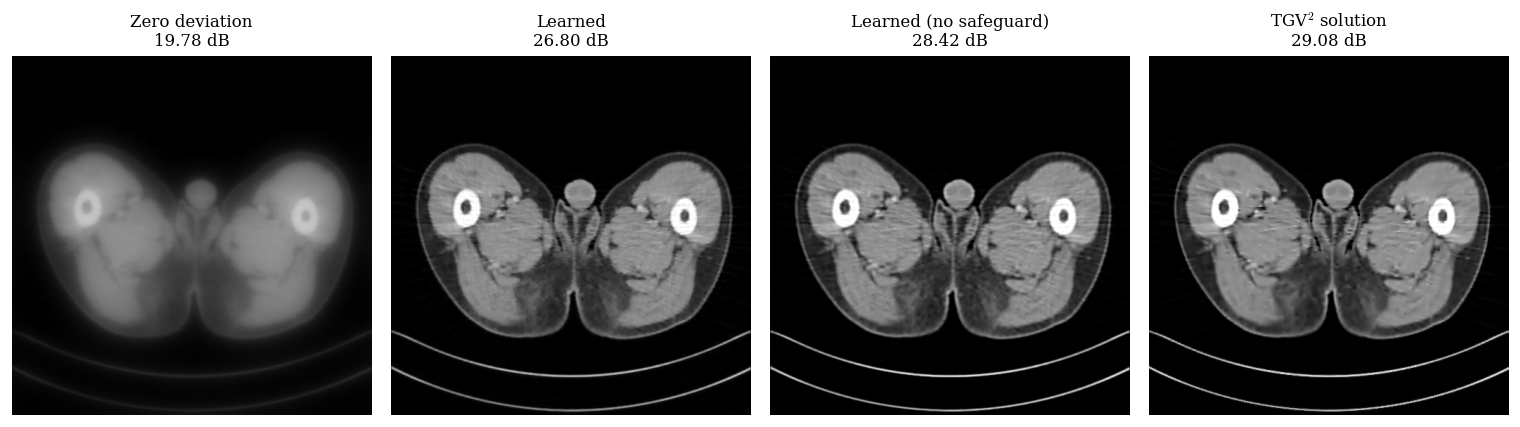

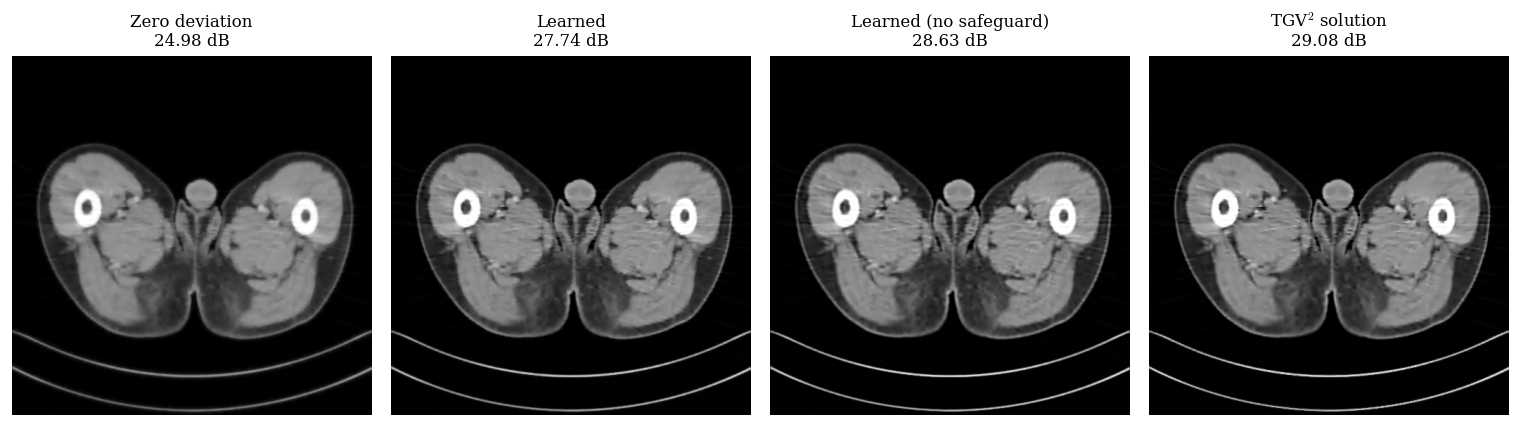

In [12]:
def gallery(n, i=0):
    # reconstruction of every method except the random control after n iterations, on slice i
    images = {f"{label}\n{rs[i]['psnr'][n]:.2f} dB": rs[i]["images"][n]
              for label, rs in results.items() if label != "Random"}
    images[f"TGV$^2$ solution\n{refs[i]['psnr']:.2f} dB"] = refs[i]["image"]
    return images

show_images(gallery(T_TRAIN), f"5_reconstructions_{T_TRAIN}_iterations", show=True)
show_images(gallery(T_LONG), f"5_reconstructions_{T_LONG}_iterations", show=True)

## 5. Time per iteration

Measured on the first slice, on a separate short run without any monitoring (the random control is
not timed). The safeguard needs the quantity $\delta_n$ and two $M$-norms, i.e. six extra evaluations
of the linear operator per iteration. The difference between "Learned (no safeguard)" and
"Zero deviation" is the cost of the network; the difference between "Learned" and
"Learned (no safeguard)" is the cost of the safeguard.

In [13]:
timing = {label: rs[0] for label, rs in results.items() if label != "Random"}
time_table(timing, refs[0]["f_star"], name="5_time_comparison")

,Time / iteration (ms),F-F* after 10 it
Method,,
Zero deviation,28,19.77
Learned,64,0.75
Learned (no safeguard),33,0.31


## 6. Larger resolution

The network is fully convolutional: the models trained at $128\times128$, with and without the
safeguard, are applied without retraining on the same slices at $512\times512$, next to the model
trained at $512\times512$ without the safeguard.

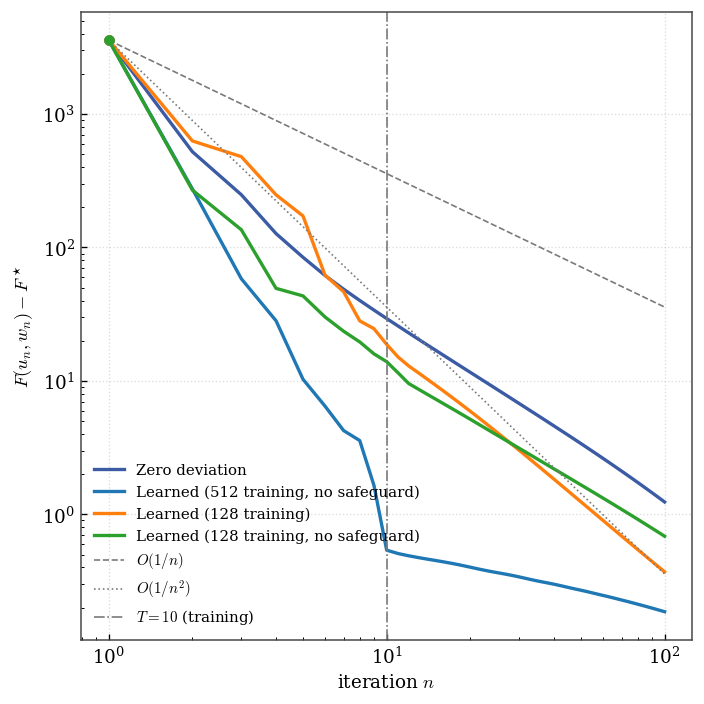

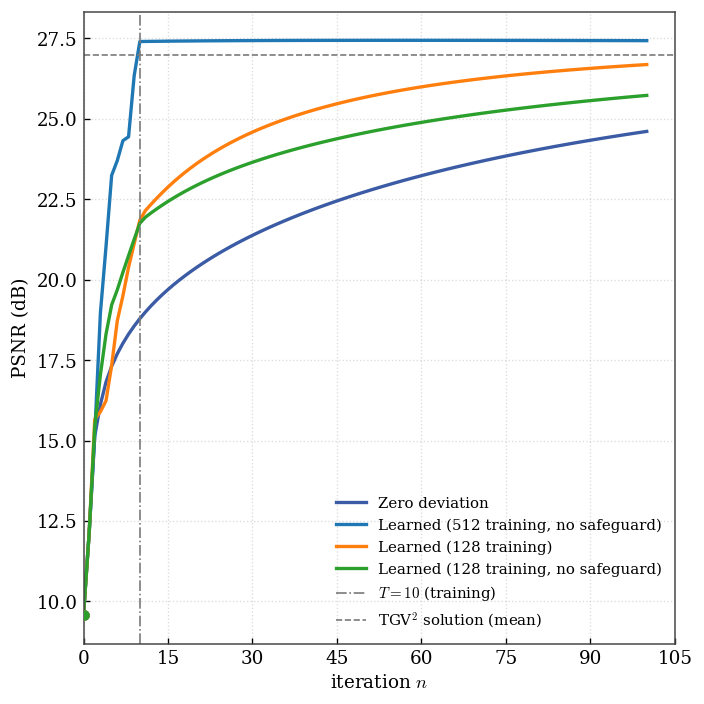

,"F-F*, 10 it.","PSNR, 10 it. (dB)","F-F*, 100 it.","PSNR, 100 it. (dB)",better at 10 it.
Method,,,,,
Zero deviation,30.6 $\pm$ 9.1,18.79 $\pm$ 0.73,1.27 $\pm$ 0.32,24.61 $\pm$ 0.39,
"Learned (512 training, no safeguard)",0.602 $\pm$ 0.32,27.40 $\pm$ 0.91,0.229 $\pm$ 0.17,27.43 $\pm$ 1.09,10/10
Learned (128 training),19.6 $\pm$ 6.2,21.85 $\pm$ 0.94,0.386 $\pm$ 0.12,26.69 $\pm$ 1.30,10/10
"Learned (128 training, no safeguard)",14.4 $\pm$ 3.8,21.75 $\pm$ 0.72,0.716 $\pm$ 0.24,25.73 $\pm$ 0.64,10/10


In [11]:
model_128, _ = load_model(CKPT_128, instances[0], T=T_TRAIN)
model_128_nosafe, _ = load_model(CKPT_128_NOSAFE, instances[0], T=T_TRAIN)
resolution = dict(
    {"Zero deviation": results["Zero deviation"],
     "Learned (512 training, no safeguard)": results["Learned (no safeguard)"]},
    **run_all({"Learned (128 training)": lambda inst: run_fbs(inst, T_LONG, model_128),
               "Learned (128 training, no safeguard)":
                   lambda inst: run_fbs(inst, T_LONG, model_128_nosafe)}),
)
gap_plot(resolution, "5_resolution")
psnr_plot(resolution, "5_resolution_psnr")
summary(resolution, "5_resolution")